In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from river import datasets
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, roc_auc_score, log_loss
)

df = pd.DataFrame(
    [{**x, "target": int(y)} for x, y in datasets.Elec2()]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (45312, 9)


,date,day,period,nswprice,nswdemand,vicprice,vicdemand,transfer,target
0,0.0,2,0.000000,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.0,2,0.021277,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.0,2,0.042553,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.0,2,0.063830,0.045485,0.314639,0.003467,0.422915,0.414912,1
4,0.0,2,0.085106,0.042482,0.251116,0.003467,0.422915,0.414912,0


In [2]:

original_features = [
    "day", "period", "nswprice", "nswdemand",
    "vicprice", "vicdemand", "transfer"
]

print("Original features:")
print(original_features)

print("\nFeatures requiring timing verification:")
print(["nswprice", "vicprice", "nswdemand",
       "vicdemand", "transfer"])

print("\nTarget distribution:")
print(df["target"].value_counts(normalize=True))

Original features:
['day', 'period', 'nswprice', 'nswdemand', 'vicprice', 'vicdemand', 'transfer']

Features requiring timing verification:
['nswprice', 'vicprice', 'nswdemand', 'vicdemand', 'transfer']

Target distribution:
target
0    0.575455
1    0.424545
Name: proportion, dtype: float64


In [3]:

lag_columns = [
    "nswprice", "nswdemand",
    "vicprice", "vicdemand", "transfer"
]

df_lagged = df.copy()

for col in lag_columns:
    df_lagged[f"{col}_lag1"] = df_lagged[col].shift(1)

# Use only lagged numeric measurements
FEATURES = [f"{col}_lag1" for col in lag_columns]

df_lagged = df_lagged.dropna(
    subset=FEATURES + ["target"]
).reset_index(drop=True)

print("Lagged dataset shape:", df_lagged.shape)
print("Model features:", FEATURES)

display(df_lagged[FEATURES + ["target"]].head())

Lagged dataset shape: (45311, 14)
Model features: ['nswprice_lag1', 'nswdemand_lag1', 'vicprice_lag1', 'vicdemand_lag1', 'transfer_lag1']


,nswprice_lag1,nswdemand_lag1,vicprice_lag1,vicdemand_lag1,transfer_lag1,target
0,0.056443,0.439155,0.003467,0.422915,0.414912,1
1,0.051699,0.415055,0.003467,0.422915,0.414912,1
2,0.051489,0.385004,0.003467,0.422915,0.414912,1
3,0.045485,0.314639,0.003467,0.422915,0.414912,0
4,0.042482,0.251116,0.003467,0.422915,0.414912,0


In [4]:

early_train = df_lagged.iloc[:5000]
recent_train = df_lagged.iloc[18000:25000]
test = df_lagged.iloc[25000:]

print("Early training:", len(early_train))
print("Recent training:", len(recent_train))
print("Future test:", len(test))

assert early_train.index.max() < test.index.min()
assert recent_train.index.max() < test.index.min()

Early training: 5000
Recent training: 7000
Future test: 20311


In [5]:

def fit_and_evaluate(train_data, test_data, name):
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )

    clf.fit(
        train_data[FEATURES],
        train_data["target"]
    )

    probabilities = clf.predict_proba(
        test_data[FEATURES]
    )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "model": name,
        "accuracy": accuracy_score(
            test_data["target"], predictions
        ),
        "roc_auc": roc_auc_score(
            test_data["target"], probabilities
        ),
        "log_loss": log_loss(
            test_data["target"], probabilities
        )
    }

    return clf, metrics


early_model, early_metrics = fit_and_evaluate(
    early_train, test, "Early model"
)

recent_model, recent_metrics = fit_and_evaluate(
    recent_train, test, "Recent model"
)

comparison = pd.DataFrame(
    [early_metrics, recent_metrics]
)

display(comparison.round(4))

,model,accuracy,roc_auc,log_loss
0,Early model,0.6675,0.7362,0.7115
1,Recent model,0.6937,0.7448,0.6221


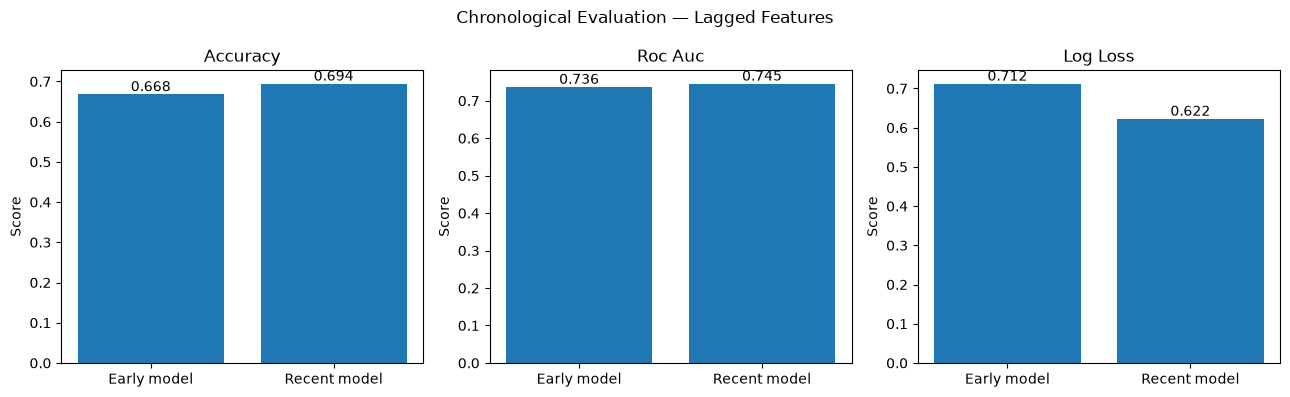

In [6]:

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

metrics = ["accuracy", "roc_auc", "log_loss"]

for ax, metric in zip(axes, metrics):
    bars = ax.bar(
        comparison["model"],
        comparison[metric]
    )

    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylabel("Score")

    for bar in bars:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f"{bar.get_height():.3f}",
            ha="center",
            va="bottom"
        )

plt.suptitle("Chronological Evaluation — Lagged Features")
plt.tight_layout()
plt.show()

In [7]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "results"
output_dir.mkdir(parents=True, exist_ok=True)

comparison.to_csv(
    output_dir / "temporal_validation.csv",
    index=False
)

# Predictions on future test data
predictions_df = pd.DataFrame({
    "observation": test.index,
    "actual": test["target"].to_numpy(),
    "early_probability": early_model.predict_proba(
        test[FEATURES]
    )[:, 1],
    "recent_probability": recent_model.predict_proba(
        test[FEATURES]
    )[:, 1]
})

predictions_df.to_csv(
    output_dir / "temporal_predictions.csv",
    index=False
)

print("Saved results to:", output_dir)

Saved results to: c:\Users\khush\drift-research\results


### Temporal Validation - Key Takeaways

This experiment evaluates two logistic regression models using lagged historical electricity-market measurements and a shared chronological test set.

- **Objective:** Reduce the risk of using contemporaneous information that may be unavailable at prediction time.
- **Method:** Compare models trained on early and more recent observations.
- **Evaluation:** Accuracy, ROC-AUC, and log loss on the same future observations.
- **Limitations:** Feature availability and target timing have not been fully verified against the original dataset documentation. A one-observation lag is a conservative modeling choice, not a complete leakage audit.
- **Conclusion:** To be completed after inspecting the experimental results.